# Chapter 28: The slope of a network

Checks [chapter 28](../../book/28-the-slope-of-a-network.md). The model is a **random ReLU network** with a scalar
score: `score(input) = readout . relu(W_k ... relu(W_1 input + bias_1) ... + bias_k)`, width 64, input dimension 64,
Gaussian weights, float64, NumPy, seeded. The slope of a layer is the spectral norm of its weight matrix (the ReLU has
slope one), so the theorem `lipschitzWith_runLayers` predicts that the steepest slope of the network is at most the
product of the spectral norms of `W_1 ... W_k` and the readout. The flip result is `le_mul_dist_of_flip`, and the
nudge result is `score_add_sign` and `abs_score_add_sub_le` for a linear model.
These are measurements, not proofs: the proofs are in `NetworkSlope.lean`. Run every cell, top to bottom.
A failed check stops the notebook.

A caveat on "steepest slope": for a piecewise linear network the true steepest slope is the largest gradient norm over
all linear pieces. A sample of inputs gives only a **lower bound** on it. So "measured is at most the bound" is a
real test (a bound that is too small would be caught), but "measured equals the bound" is not claimed.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 28
WIDTH = 64
INPUT_DIM = 64
NETS_PER_DEPTH = 12
DEPTHS = list(range(1, 9))
SAMPLES_PER_NET = 3000
INPUT_SCALES = (0.1, 0.5, 1.0, 3.0)


def make_network(depth, gain, generator, activation_slope=1.0):
    """Weights W_1..W_depth, biases, and a readout row."""
    weights, biases = [], []
    previous = INPUT_DIM
    for _ in range(depth):
        weights.append(generator.standard_normal((WIDTH, previous)) * gain / np.sqrt(previous))
        biases.append(generator.standard_normal(WIDTH) * 0.1)
        previous = WIDTH
    readout = generator.standard_normal(WIDTH) * gain / np.sqrt(WIDTH)
    return {"weights": weights, "biases": biases, "readout": readout, "activation_slope": activation_slope}


def get_layer_slopes(network):
    """Spectral norm of each weight matrix, then the norm of the readout row."""
    slopes = [float(np.linalg.norm(weight, 2)) for weight in network["weights"]]
    slopes.append(float(np.linalg.norm(network["readout"])))
    return slopes


def get_slope_product(network):
    """The product of the layers' slope limits (the activation slope is not included: it is assumed to be one)."""
    return float(np.prod(get_layer_slopes(network)))


def run_network(network, inputs):
    """Score and gradient with respect to the input, for a batch of inputs (rows)."""
    activation = inputs
    masks = []
    for weight, bias in zip(network["weights"], network["biases"]):
        pre = activation @ weight.T + bias
        masks.append((pre > 0).astype(float))
        activation = network["activation_slope"] * np.maximum(pre, 0.0)
    scores = activation @ network["readout"]
    gradient = np.tile(network["readout"], (len(inputs), 1))
    for weight, mask in zip(reversed(network["weights"]), reversed(masks)):
        gradient = (gradient * mask * network["activation_slope"]) @ weight
    return scores, gradient


def measure_steepest_slope(network, generator):
    """Largest gradient norm over inputs at several scales: a lower bound on the true steepest slope."""
    best = 0.0
    for scale in INPUT_SCALES:
        inputs = generator.standard_normal((SAMPLES_PER_NET // len(INPUT_SCALES), INPUT_DIM)) * scale
        _, gradient = run_network(network, inputs)
        best = max(best, float(np.linalg.norm(gradient, axis=1).max()))
    return best


def measure_pair_slope(network, generator, pair_count=3000):
    """Largest |score(a) - score(b)| / |a - b| over random pairs, near and far."""
    first = generator.standard_normal((pair_count, INPUT_DIM))
    step = generator.standard_normal((pair_count, INPUT_DIM)) * np.logspace(-3, 0, pair_count)[:, None]
    scores_first, _ = run_network(network, first)
    scores_second, _ = run_network(network, first + step)
    return float((np.abs(scores_first - scores_second) / np.linalg.norm(step, axis=1)).max())

## Claim 1: the slope of a stack is at most the product of the slopes (`lipschitzWith_runLayers`, `lipschitzWith_relu`, `lipschitzWith_activation_comp`)

**Prediction.** For every random network, at depths 1 to 8, the largest gradient norm found and the largest
pair ratio are both at most the product of the spectral norms of the layers and the readout. The gradient is held
down by the same product (the transpose result, `norm_adjoint_comp_le`), so one check covers both.
A network whose measured slope exceeded the product would count against the claim. Weights have a random gain in
0.4 to 0.6 per net, so the product ranges widely, and each net has its own bound.

I also expect the ratio measured over bound to **fall with depth**: the bound lines the layers' worst directions up,
a random network does not. I assert that the median ratio at depth 8 is below the median at depth 1. That is a
prediction about random networks, not a claim of the chapter.

**Control, bound reached.** With the identity as every weight matrix and positive inputs, the ReLU does nothing, so the
slope is exactly the product (one). The measured slope must equal the bound there.

**Control, hypothesis broken.** Replace the ReLU by `2 * relu`, an activation of slope 2, but keep the product of
weight norms as the claimed bound. The hypothesis of the theorem is that each layer has the slope in the list, so the
claimed list is now wrong. The measured slope must then exceed the claimed bound.

In [2]:
generator = np.random.default_rng(SEED)
rows = []
for depth in DEPTHS:
    for _ in range(NETS_PER_DEPTH):
        gain = generator.uniform(0.4, 0.6)
        network = make_network(depth, gain, generator)
        bound = get_slope_product(network)
        steepest_found = measure_steepest_slope(network, generator)
        pair_slope = measure_pair_slope(network, generator)
        rows.append({"depth": depth, "bound": bound, "steepest": steepest_found, "pair": pair_slope})

depths = np.array([row["depth"] for row in rows])
bounds = np.array([row["bound"] for row in rows])
steepest = np.array([row["steepest"] for row in rows])
pair_slopes = np.array([row["pair"] for row in rows])
ratios = steepest / bounds

report(f"gradient norm <= product of layer slopes, for all {len(rows)} networks", bool(np.all(steepest <= bounds * (1 + 1e-9))),
       f"largest ratio {ratios.max():.3f}")
report("pair ratio |score(a) - score(b)| / |a - b| <= product, for all networks", bool(np.all(pair_slopes <= bounds * (1 + 1e-9))),
       f"largest ratio {(pair_slopes / bounds).max():.3f}")
median_by_depth = {depth: float(np.median(ratios[depths == depth])) for depth in DEPTHS}
print("median measured / bound by depth: " + ", ".join(f"{depth}: {value:.3f}" for depth, value in median_by_depth.items()))
report("the ratio measured / bound falls with depth (median at depth 8 below median at depth 1)",
       median_by_depth[8] < median_by_depth[1], f"{median_by_depth[8]:.3f} against {median_by_depth[1]:.3f}")

# Control: the bound is reached when nothing is lost.
generator = np.random.default_rng(SEED + 1)
identity_network = {"weights": [np.eye(WIDTH)] * 4, "biases": [np.zeros(WIDTH)] * 4,
                    "readout": np.ones(WIDTH) / np.sqrt(WIDTH), "activation_slope": 1.0}
positive_inputs = np.abs(generator.standard_normal((500, WIDTH))) + 0.1
_, identity_gradient = run_network(identity_network, positive_inputs)
identity_slope = float(np.linalg.norm(identity_gradient, axis=1).max())
identity_bound = get_slope_product(identity_network)
report("control: identity layers on positive inputs reach the bound exactly", abs(identity_slope - identity_bound) < 1e-9,
       f"measured {identity_slope:.6f}, bound {identity_bound:.6f}")

# Control: a slope-2 activation breaks the hypothesis.
doubled_network = dict(identity_network, activation_slope=2.0)
_, doubled_gradient = run_network(doubled_network, positive_inputs)
doubled_slope = float(np.linalg.norm(doubled_gradient, axis=1).max())
claimed_bound = get_slope_product(doubled_network)      # product of weight norms only, which assumed slope one
report("control: with activation slope 2 the measured slope exceeds the claimed product", doubled_slope > claimed_bound * 1.5,
       f"measured {doubled_slope:.2f}, claimed bound {claimed_bound:.2f}, factor {doubled_slope / claimed_bound:.1f}")

[PASS] gradient norm <= product of layer slopes, for all 96 networks  (largest ratio 0.539)
[PASS] pair ratio |score(a) - score(b)| / |a - b| <= product, for all networks  (largest ratio 0.189)
median measured / bound by depth: 1: 0.513, 2: 0.209, 3: 0.089, 4: 0.032, 5: 0.011, 6: 0.004, 7: 0.002, 8: 0.001
[PASS] the ratio measured / bound falls with depth (median at depth 8 below median at depth 1)  (0.001 against 0.513)
[PASS] control: identity layers on positive inputs reach the bound exactly  (measured 1.000000, bound 1.000000)
[PASS] control: with activation slope 2 the measured slope exceeds the claimed product  (measured 16.00, claimed bound 1.00, factor 16.0)


True

wrote book/figures/28-measured-against-product.png


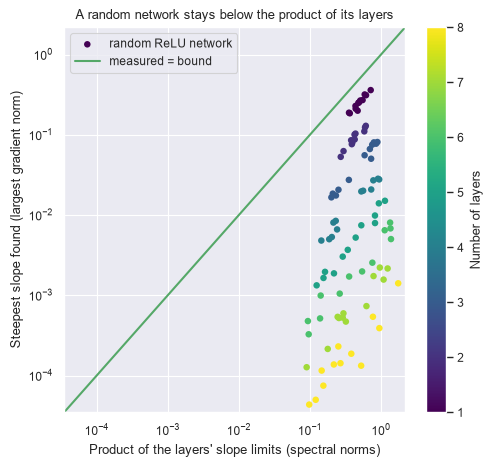

In [3]:
figure, axis = plt.subplots(figsize=(5.5, 5.0))
scatter = axis.scatter(bounds, steepest, c=depths, cmap="viridis", s=22, edgecolor="none", label="random ReLU network")
low, high = min(bounds.min(), steepest.min()) * 0.8, bounds.max() * 1.25
axis.plot([low, high], [low, high], color=BOUND, linewidth=1.5, label="measured = bound")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlim(low, high)
axis.set_ylim(low, high)
axis.set_xlabel("Product of the layers' slope limits (spectral norms)")
axis.set_ylabel("Steepest slope found (largest gradient norm)")
axis.set_title("A random network stays below the product of its layers")
colorbar = figure.colorbar(scatter, ax=axis)
colorbar.set_label("Number of layers")
axis.legend(loc="upper left")
save_figure(figure, "28-measured-against-product")
plt.show()

## Claim 2: flipping a classifier takes a move of at least score over slope (`le_mul_dist_of_flip`)

**Prediction.** Take a positive score at an input and search for the nearest input where the score is at most zero.
Any flipping input, however found, is at distance at least `score / bound`, where `bound` is the product of the
layers' slopes. The search is a normalised gradient attack with a bisection on the last step, plus 200 random
directions; it finds *some* flips, so it can only show a distance that is too small, and a distance below
`score / bound` would count against the theorem. The attack should stay above the limit by a factor, because the
product is not reached (claim 1); I report that factor.

**Control.** The doubled-activation network of claim 1, with the same claimed bound. Its flips must come at distances
**below** `score / claimed bound`, because the claimed slope is too small.

In [4]:
def find_flip_distance(network, start, generator, step_size=0.02, max_steps=2000, random_directions=200):
    """Smallest distance found from `start` to an input with score <= 0, or infinity if none is found."""
    best = np.inf
    # Gradient attack: step against the gradient until the score is at most zero, then bisect the last step.
    point = start.copy()
    for _ in range(max_steps):
        _, gradient = run_network(network, point[None, :])
        direction = -gradient[0] / max(np.linalg.norm(gradient[0]), 1e-300)
        trial_score, _ = run_network(network, (point + step_size * direction)[None, :])
        if trial_score[0] <= 0.0:
            low, high = 0.0, step_size
            for _ in range(50):
                middle = (low + high) / 2
                middle_score, _ = run_network(network, (point + middle * direction)[None, :])
                low, high = (low, middle) if middle_score[0] <= 0.0 else (middle, high)
            best = min(best, float(np.linalg.norm(point + high * direction - start)))
            break
        point = point + step_size * direction
    # Random directions: walk out along each ray until some score is at most zero.
    directions = generator.standard_normal((random_directions, len(start)))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    for radius in np.linspace(0.05, 15.0, 300):
        scores, _ = run_network(network, start + radius * directions)
        if np.any(scores <= 0.0):
            best = min(best, float(radius))
            break
    return best


generator = np.random.default_rng(SEED + 2)
flip_rows = []
for depth in (1, 2, 3, 4):
    for _ in range(8):
        gain = generator.uniform(0.4, 0.6)
        network = make_network(depth, gain, generator)
        bound = get_slope_product(network)
        starts = generator.standard_normal((6, INPUT_DIM))
        scores, _ = run_network(network, starts)
        for start, score in zip(starts, scores):
            if score <= 0.0:
                continue
            distance = find_flip_distance(network, start, generator)
            if np.isfinite(distance):
                flip_rows.append({"depth": depth, "score": float(score), "bound": bound, "distance": distance,
                                  "limit": float(score) / bound})

limits = np.array([row["limit"] for row in flip_rows])
distances = np.array([row["distance"] for row in flip_rows])
flip_ratios = distances / limits
report(f"every flip found is at least score / bound away ({len(flip_rows)} flips)", bool(np.all(distances >= limits * (1 - 1e-9))),
       f"smallest distance over limit {flip_ratios.min():.2f}, median {np.median(flip_ratios):.2f}")

# Control: slope-2 activations, claimed bound from the weights alone.
generator = np.random.default_rng(SEED + 3)
control_rows = []
for _ in range(10):
    start = np.abs(generator.standard_normal(WIDTH)) + 0.5
    score = float(run_network(doubled_network, start[None, :])[0][0])
    distance = find_flip_distance(doubled_network, start, generator, step_size=0.05)
    control_rows.append({"limit": score / claimed_bound, "distance": distance})
control_limits = np.array([row["limit"] for row in control_rows])
control_distances = np.array([row["distance"] for row in control_rows])
control_ratios = control_distances / control_limits
report("control: with the wrong claimed slope, flips come closer than score / claimed bound",
       bool(np.all(control_distances < control_limits)),
       f"distance over limit from {control_ratios.min():.2f} to {control_ratios.max():.2f}")

[PASS] every flip found is at least score / bound away (100 flips)  (smallest distance over limit 2.41, median 11.33)


[PASS] control: with the wrong claimed slope, flips come closer than score / claimed bound  (distance over limit from 0.07 to 0.07)


True

wrote book/figures/28-flip-distance.png


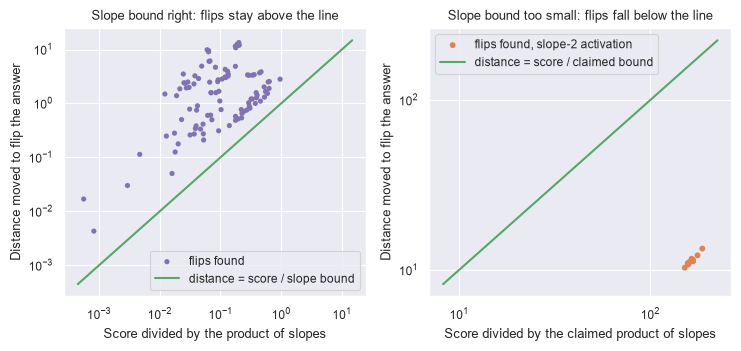

In [5]:
figure, (left, right) = plt.subplots(1, 2, figsize=(7.5, 3.6))
left.scatter(limits, distances, color=MODEL, s=14, edgecolor="none", label="flips found")
top = max(limits.max(), distances.max()) * 1.1
bottom = min(limits.min(), distances.min()) * 0.8
left.plot([bottom, top], [bottom, top], color=BOUND, linewidth=1.5, label="distance = score / slope bound")
left.set_xscale("log")
left.set_yscale("log")
left.set_xlabel("Score divided by the product of slopes")
left.set_ylabel("Distance moved to flip the answer")
left.set_title("Slope bound right: flips stay above the line")
left.legend(loc="lower right")

right.scatter(control_limits, control_distances, color=VERTICAL, s=18, edgecolor="none", label="flips found, slope-2 activation")
top = max(control_limits.max(), control_distances.max()) * 1.2
bottom = min(control_limits.min(), control_distances.min()) * 0.8
right.plot([bottom, top], [bottom, top], color=BOUND, linewidth=1.5, label="distance = score / claimed bound")
right.set_xscale("log")
right.set_yscale("log")
right.set_xlabel("Score divided by the claimed product of slopes")
right.set_ylabel("Distance moved to flip the answer")
right.set_title("Slope bound too small: flips fall below the line")
right.legend(loc="upper left")
figure.tight_layout()
save_figure(figure, "28-flip-distance")
plt.show()

## Claim 3: the nudge on a linear model (`score_add_sign`, `abs_score_add_sub_le`)

**Prediction.** For a linear model, nudging every input by `nudge` in the direction of the sign of its weight changes
the score by exactly `nudge * sum of |weights|`, and no nudge of at most `nudge` per input changes it by more.
Checked on the chapter's example (weights 2, -3, 1, nudge 0.05: change 0.3), on the 1000-input example (every weight
of size 0.01, nudge 0.01: change 0.1), and on random weights in 100 dimensions against 20 000 random nudges in the
box, and on all 2^12 corners of the box in 12 dimensions. A random nudge that changed the score by more than the
bound would count against the claim. The control: a nudge twice as large (outside the box) must change the score by
twice as much, past the bound.

In [6]:
def get_score_change(weights, nudge_vector):
    return float(weights @ nudge_vector)


example_weights = np.array([2.0, -3.0, 1.0])
example_change = get_score_change(example_weights, 0.05 * np.sign(example_weights))
report("chapter example: change 0.3 = 0.05 * (2 + 3 + 1)", abs(example_change - 0.05 * np.abs(example_weights).sum()) < 1e-12,
       f"change {example_change:.4f}")

thousand_weights = np.full(1000, 0.01)
thousand_change = get_score_change(thousand_weights, 0.01 * np.sign(thousand_weights))
report("1000 inputs, every weight 0.01, nudge 0.01: the score moves by 0.1", abs(thousand_change - 0.1) < 1e-12,
       f"change {thousand_change:.6f}")

generator = np.random.default_rng(SEED + 4)
random_weights = generator.standard_normal(100)
NUDGE = 0.01
exact_change = get_score_change(random_weights, NUDGE * np.sign(random_weights))
size_sum = float(np.abs(random_weights).sum())
random_nudges = generator.uniform(-NUDGE, NUDGE, size=(20000, 100))
largest_random = float(np.abs(random_nudges @ random_weights).max())
small_weights = generator.standard_normal(12)
corner_signs = np.array([[1 if (corner >> bit) & 1 else -1 for bit in range(12)] for corner in range(2 ** 12)])
largest_corner = float(np.abs(NUDGE * corner_signs @ small_weights).max())
small_size_sum = float(np.abs(small_weights).sum())
report("the sign nudge changes the score by exactly nudge * sum of |weights|", abs(exact_change - NUDGE * size_sum) < 1e-12,
       f"change {exact_change:.4f}, nudge times sum {NUDGE * size_sum:.4f}")
report("20 000 random nudges in the box never beat the bound", largest_random <= NUDGE * size_sum + 1e-12,
       f"largest {largest_random:.4f} of {NUDGE * size_sum:.4f} ({largest_random / (NUDGE * size_sum):.2f})")
report("over all 4096 corners of the box in 12 dimensions the best equals the bound and none beats it",
       abs(largest_corner - NUDGE * small_size_sum) < 1e-12, f"best corner {largest_corner:.5f}, bound {NUDGE * small_size_sum:.5f}")
doubled_change = get_score_change(random_weights, 2 * NUDGE * np.sign(random_weights))
report("control: a nudge twice the limit goes past the bound", doubled_change > NUDGE * size_sum * 1.99,
       f"change {doubled_change:.4f} against bound {NUDGE * size_sum:.4f}")

[PASS] chapter example: change 0.3 = 0.05 * (2 + 3 + 1)  (change 0.3000)
[PASS] 1000 inputs, every weight 0.01, nudge 0.01: the score moves by 0.1  (change 0.100000)
[PASS] the sign nudge changes the score by exactly nudge * sum of |weights|  (change 0.7602, nudge times sum 0.7602)
[PASS] 20 000 random nudges in the box never beat the bound  (largest 0.2334 of 0.7602 (0.31))
[PASS] over all 4096 corners of the box in 12 dimensions the best equals the bound and none beats it  (best corner 0.08903, bound 0.08903)
[PASS] control: a nudge twice the limit goes past the bound  (change 1.5205 against bound 0.7602)


True

## Summary

Built from the numbers computed above.

In [7]:
print(f"claim 1: {len(rows)} random nets, depths 1 to 8: largest measured / bound {ratios.max():.3f}; "
      f"median {median_by_depth[1]:.3f} at depth 1, {median_by_depth[8]:.3f} at depth 8; "
      f"identity control {identity_slope / identity_bound:.3f}; slope-2 control factor {doubled_slope / claimed_bound:.1f}")
print(f"claim 2: {len(flip_rows)} flips: distance over score / bound from {flip_ratios.min():.2f} to {flip_ratios.max():.2f} "
      f"(median {np.median(flip_ratios):.2f}); control {control_ratios.min():.2f} to {control_ratios.max():.2f}")
print(f"claim 3: best random nudge reached {largest_random / (NUDGE * size_sum):.2f} of the bound, the best corner {largest_corner / (NUDGE * small_size_sum):.2f}")

claim 1: 96 random nets, depths 1 to 8: largest measured / bound 0.539; median 0.513 at depth 1, 0.001 at depth 8; identity control 1.000; slope-2 control factor 16.0
claim 2: 100 flips: distance over score / bound from 2.41 to 163.36 (median 11.33); control 0.07 to 0.07
claim 3: best random nudge reached 0.31 of the bound, the best corner 1.00
